# Error analysis: where the 11:00 forecasts fail

This notebook analyses the errors of the two 11:00 models, `gbm` and `linear`, over the backtest from 1 January 2024 to 24 October 2026 (1,028 delivery days). The forecasts come from the `predictions` table, on the hours every model forecast, and are scored as in `evaluate.py` by their mean absolute error (MAE), with the weekly naive as the benchmark. `gbm_papers`, the papers' setup, is the same trees given day d's renewables forecast (wind plus solar), published at 18:00 on d−1, after gate closure; the 11:00 models see the forecast for d−1, so `gbm_papers` serves as a comparison only.

The notebook runs from the error distribution across all hours to the ten worst days, a case study of the worst day, and three drivers: the renewables forecast, analogue days and market coupling. Running it needs the database the pipeline builds (see the README).

In [1]:
import calendar
import math
from statistics import NormalDist

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from pl_dayahead import store
from pl_dayahead.config import MW_PER_GW
from pl_dayahead.evaluate import common_hours
from pl_dayahead.features import build_features
from pl_dayahead.models import MODELS
from pl_dayahead.style import (BASELINE, INK, INK_2, MODEL_COLOURS, SOURCE_BACKTEST, SURFACE, captioned,
                               save, use_notebook_style, whole)
from pl_dayahead.timeutils import LOCAL_TZ, day_label, delivery_index, is_holiday

use_notebook_style()  # the chart settings of both notebooks; each model keeps its colour in MODEL_COLOURS

In [2]:
con = store.connect()
predictions = con.sql('SELECT model, ts_utc, prediction, actual FROM predictions').df()
hourly = con.sql('SELECT * FROM hourly').df()
con.close()

# The renewables forecast (wind plus solar) as the backtest builds it: renewables_fcst_lag_1d is the one gbm and
# the linear model saw at 11:00, the forecast for the day before delivery; renewables_fcst is day d's own, published
# at 18:00, which only the papers' setup is given. residual_load_fcst is the load forecast minus renewables_fcst.
features, _ = build_features(hourly)
forecasts = hourly[['ts_utc', 'load_fcst', 'wind_fcst', 'solar_fcst', 'residual_load_fcst']].merge(
    features[['ts_utc', 'renewables_fcst', 'renewables_fcst_lag_1d']], on='ts_utc')

# For reference only: gbm_papers, the papers' setup, and naive_similar_day, the second naive benchmark (section 5).
STUDIED_MODELS = ['gbm', 'linear', 'naive_weekly', 'naive_similar_day', 'gbm_papers']

# One row per hour that every registered model forecast, as evaluate.py scores them, with the forecasts studied here.
hours = (common_hours(predictions[predictions['model'].isin(MODELS)])[STUDIED_MODELS + ['actual']].reset_index()
         .merge(forecasts, on='ts_utc', how='left'))
hours['residual_seen'] = hours['load_fcst'] - hours['renewables_fcst_lag_1d']  # residual load as gbm saw it at 11:00

# Warsaw time, delivery day and hour of day, as in notebook 01.
hours['local'] = hours['ts_utc'].dt.tz_convert(LOCAL_TZ)
hours['day'] = pd.to_datetime(hours['local'].dt.date)
hours['hour'] = hours['local'].dt.hour

for model in STUDIED_MODELS:
    hours[f'err_{model}'] = hours[model] - hours['actual']  # positive: over-forecast
    hours[f'abs_{model}'] = hours[f'err_{model}'].abs()

print(f"{len(hours):,} hours on {hours['day'].nunique():,} delivery days, "
      f"{day_label(hours['day'].min(), weekday=False)} to {day_label(hours['day'].max(), weekday=False)}")
print('MAE, EUR/MWh (must match evaluate.py): ' + ', '.join(f"{model} {hours[f'abs_{model}'].mean():.2f}" for model in STUDIED_MODELS))

24,671 hours on 1,028 delivery days, 1 Jan 2024 to 24 Oct 2026
MAE, EUR/MWh (must match evaluate.py): gbm 21.18, linear 21.30, naive_weekly 32.56, naive_similar_day 27.34, gbm_papers 16.95


## 1. Error concentration

How `gbm`'s error is spread across days and hours: its daily MAE, and the share of its absolute error held by the worst days and hours, against half-normal errors (light tails) and exponential errors (the usual boundary of heavy tails).

In [3]:
# One row per delivery day: each model's MAE, gbm's bias, the price and forecast range, and day d's average
# wind forecast. The worst days are picked from this table.
daily = hours.groupby('day').agg(
    mae_gbm=('abs_gbm', 'mean'), mae_linear=('abs_linear', 'mean'), mae_naive=('abs_naive_weekly', 'mean'),
    mae_papers=('abs_gbm_papers', 'mean'), bias_gbm=('err_gbm', 'mean'),
    actual_mean=('actual', 'mean'), actual_min=('actual', 'min'), actual_max=('actual', 'max'),
    gbm_min=('gbm', 'min'), gbm_max=('gbm', 'max'), wind_gw=('wind_fcst', 'mean'),
)
daily['wind_gw'] /= MW_PER_GW

# The previous calendar day's average price, looked up by date so a missing day can never
# make a day compare itself with the wrong neighbour.
previous = daily['actual_mean'].reindex(daily.index - pd.Timedelta(days=1)).to_numpy()
daily['jump'] = daily['actual_mean'] - previous

daily['weekday'] = daily.index.day_name().str[:3]
daily['holiday'] = is_holiday(daily.index.to_series()).to_numpy()

# The worst 1% of days by gbm's MAE, studied from section 3 on.
N_WORST = round(len(daily) / 100)
worst = daily.sort_values('mae_gbm', ascending=False).head(N_WORST)

# How large the daily error is on the median day and on bad days, for both models.
levels = [0.5, 0.9, 0.99, 1.0]
spread = pd.DataFrame(
    {'Gradient-boosted trees (gbm)': daily['mae_gbm'].quantile(levels).to_numpy(),
     'Linear model': daily['mae_linear'].quantile(levels).to_numpy()},
    index=['median day', '90th percentile', '99th percentile', 'worst day'],
)
median_day = daily['mae_gbm'].median()
print(f"The worst 1% of days, studied from section 3 on: {N_WORST} days, with gbm's MAE from "
      f"{worst['mae_gbm'].min():.1f} to {worst['mae_gbm'].max():.1f} EUR/MWh, {worst['mae_gbm'].min() / median_day:.1f} "
      f"to {worst['mae_gbm'].max() / median_day:.1f} times the median day's {median_day:.1f}")
spread.style.format('{:.1f}').pipe(captioned, f'Daily MAE over {len(daily):,} delivery days, EUR/MWh')

The worst 1% of days, studied from section 3 on: 10 days, with gbm's MAE from 64.4 to 112.5 EUR/MWh, 3.4 to 6.0 times the median day's 18.7


,Gradient-boosted trees (gbm),Linear model
median day,18.7,18.8
90th percentile,36.1,35.3
99th percentile,63.0,61.3
worst day,112.5,116.4


In [4]:
# Share of gbm's total absolute error held by the worst days and hours, against three reference distributions.
# Days are ranked by MAE, as above, and their whole day's error is counted.
SHARES = [1, 5, 10, 25, 50]
day_error = hours.groupby('day')['abs_gbm'].sum().reindex(daily['mae_gbm'].sort_values(ascending=False).index)
hour_error = hours['abs_gbm'].sort_values(ascending=False)


def top_share(ordered, percent):
    # Share of the total held by the first percent% of a series sorted from worst to best.
    count = max(1, round(len(ordered) * percent / 100))
    return 100 * ordered.iloc[:count].sum() / ordered.sum()


# The reference shares in closed form: the share of the total held by the largest percent% of values. For half-normal
# errors it is exp(-t²/2), with t the normal quantile at 1 - percent/200; for exponential errors it is
# q(1 + ln(1/q)), with q = percent/100.
def half_normal_share(percent):
    return 100 * math.exp(-NormalDist().inv_cdf(1 - percent / 200) ** 2 / 2)


def exponential_share(percent):
    q = percent / 100
    return 100 * q * (1 + math.log(1 / q))


concentration = pd.DataFrame({
    ('reference', 'uniform'): SHARES,
    ('reference', 'half-normal'): [half_normal_share(percent) for percent in SHARES],
    ('reference', 'exponential'): [exponential_share(percent) for percent in SHARES],
    ('gbm', 'worst days'): [top_share(day_error, percent) for percent in SHARES],
    ('gbm', 'worst hours'): [top_share(hour_error, percent) for percent in SHARES],
}, index=[f'worst {percent}%' for percent in SHARES])

worst_hours = hours.loc[hour_error.index[:round(len(hour_error) / 100)], 'day']
print(f"The worst 1% of hours, {len(worst_hours)}, fall on {worst_hours.nunique()} different days")
(concentration.style.format('{:.1f}').format('{:.0f}', subset=[('reference', 'uniform')])
 .pipe(captioned, "Share of gbm's absolute error held by the worst days and hours, against three reference distributions (%)"))

The worst 1% of hours, 247, fall on 111 different days


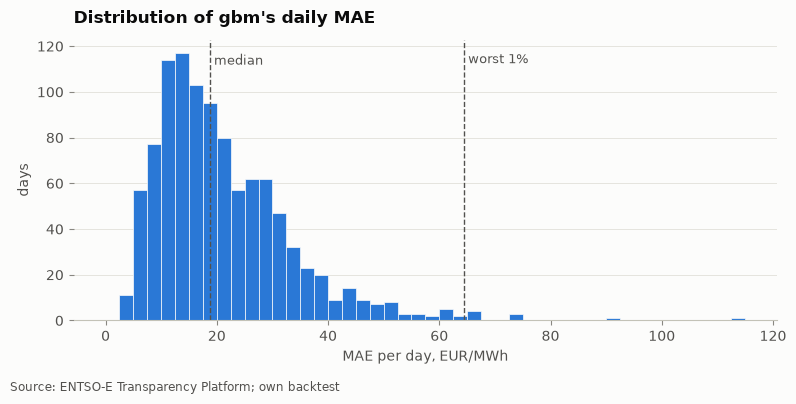

In [5]:
# Chart 1: gbm's average forecast error per day.
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(daily['mae_gbm'], bins=np.arange(0, daily['mae_gbm'].max() + 2.5, 2.5),
        color=MODEL_COLOURS['gbm'], edgecolor=SURFACE, linewidth=0.5)
for mae_value, name in [(daily['mae_gbm'].median(), 'median'), (worst['mae_gbm'].min(), 'worst 1%')]:
    ax.axvline(mae_value, color=INK_2, lw=1, ls='--')
    ax.text(mae_value + 0.8, ax.get_ylim()[1] * 0.95, name, fontsize=9, color=INK_2, va='top')
ax.set_title("Distribution of gbm's daily MAE")
ax.set_xlabel('MAE per day, EUR/MWh')
ax.set_ylabel('days')
save(fig, 'daily_error_distribution.png', SOURCE_BACKTEST)

- The worst 1% of hours carry 7.9% of the error, above the exponential's 5.6%, and stay above it at every cut-off: the hourly error is heavy-tailed.
- The worst 1% of days carry 3.5%, below the half-normal's 3.6%, and stay below it at every cut-off: the daily error is not concentrated. The 247 worst hours fall on 111 days.
- Daily MAE is 18.7 EUR/MWh on the median day and 64.4 to 112.5 on the worst 1%. `linear` is similar: 18.8 and 116.4.

## 2. Error by time and price level

The error is concentrated in hours, not days. This section splits it by what is known before the auction, the month, hour and day type, and then by the actual price. The error is forecast minus actual and the bias is its mean, so a negative bias is an under-forecast.

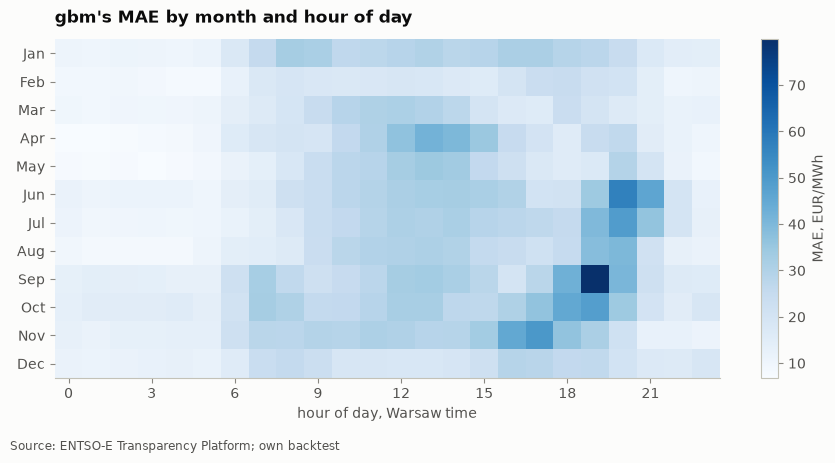

Worst hour by month: Jan 08:00 32; Feb 18:00 24; Mar 12:00 31; Apr 13:00 42; May 13:00 34; Jun 20:00 57; Jul 20:00 49; Aug 20:00 40; Sep 19:00 80; Oct 19:00 48; Nov 17:00 50; Dec 16:00 29
Hours starting 00:00 to 05:00: at most 16 EUR/MWh in any month; all hours together: 21.2


In [6]:
# Chart 2: gbm's average forecast error by month and hour of day.
by_month_hour = hours.groupby([hours['local'].dt.month, 'hour'])['abs_gbm'].mean().unstack()

fig, ax = plt.subplots(figsize=(9, 4.6))
image = ax.imshow(by_month_hour, cmap='Blues', aspect='auto')
ax.set_xticks(range(0, 24, 3))
ax.set_yticks(range(12), [calendar.month_abbr[month] for month in by_month_hour.index])
ax.grid(False)
ax.set_title("gbm's MAE by month and hour of day")
ax.set_xlabel('hour of day, Warsaw time')
fig.colorbar(image, ax=ax, label='MAE, EUR/MWh')
save(fig, 'error_by_month_hour.png', SOURCE_BACKTEST)
plt.show()

# The numbers behind the chart: each month's worst hour, and the worst night hour of the year.
worst_hour = by_month_hour.idxmax(axis=1)
print('Worst hour by month: ' + '; '.join(
    f'{calendar.month_abbr[month]} {worst_hour[month]:02d}:00 {by_month_hour.loc[month, worst_hour[month]]:.0f}' for month in by_month_hour.index))
print(f"Hours starting 00:00 to 05:00: at most {by_month_hour.loc[:, 0:5].max().max():.0f} EUR/MWh in any month; "
      f"all hours together: {hours['abs_gbm'].mean():.1f}")

- Summer and autumn evenings are the weakest: from June to October the worst hour is 19:00 or 20:00, up to 80 EUR/MWh at 19:00 in September, against 21.2 over all hours. It moves earlier with sunset, to 17:00 in November and 16:00 in December.
- From March to May the error peaks at midday, at 31 to 42 EUR/MWh at 12:00 or 13:00, with the solar peak.
- Nights are accurate: 16 EUR/MWh or less from 00:00 to 06:00 in every month.
- All three patterns are known before the auction, so a desk can discount the forecast in advance.

In [7]:
# Error by type of day. A holiday that falls on a Saturday counts as a holiday.
weekday = hours['local'].dt.dayofweek
holiday = hours['day'].map(daily['holiday']).astype(bool)
day_type = np.select([holiday | (weekday == 6), weekday == 5], ['Sunday or holiday', 'Saturday'], 'Working day')

by_type = hours.groupby(day_type)
(pd.DataFrame({
    'share of hours (%)': 100 * by_type.size() / len(hours),
    'share of gbm error (%)': 100 * by_type['abs_gbm'].sum() / hours['abs_gbm'].sum(),
    'MAE gbm': by_type['abs_gbm'].mean(),
    'MAE linear model': by_type['abs_linear'].mean(),
    'gbm minus linear model': by_type['abs_gbm'].mean() - by_type['abs_linear'].mean(),
}).reindex(['Working day', 'Saturday', 'Sunday or holiday'])
 .style.format('{:.1f}').pipe(captioned, 'Error by type of day; MAE in EUR/MWh'))

,share of hours (%),share of gbm error (%),MAE gbm,MAE linear model,gbm minus linear model
Working day,69.1,70.7,21.7,21.9,-0.2
Saturday,13.9,13.3,20.3,19.9,0.3
Sunday or holiday,17.0,16.0,19.9,20.2,-0.3


- Day type matters little: `gbm`'s MAE is 21.7 EUR/MWh on working days, 20.3 on Saturdays and 19.9 on Sundays and holidays, with `linear` within 0.3 on each.

In [8]:
PRICE_BANDS = [-np.inf, 0, 50, 100, 150, 250, np.inf]
BAND_LABELS = ['below 0', '0 to 50', '50 to 100', '100 to 150', '150 to 250', '250 and above']
# right=False makes each band include its lower edge: 0 goes in '0 to 50', 250 in '250 and above'.
hours['band'] = pd.cut(hours['actual'], PRICE_BANDS, labels=BAND_LABELS, right=False)

by_band = hours.groupby('band', observed=False)
regimes = pd.DataFrame({
    'share of hours (%)': 100 * by_band.size() / len(hours),
    'share of gbm error (%)': 100 * by_band['abs_gbm'].sum() / hours['abs_gbm'].sum(),
    'MAE gbm': by_band['abs_gbm'].mean(),
    'MAE linear model': by_band['abs_linear'].mean(),
    'gbm minus linear model': by_band['abs_gbm'].mean() - by_band['abs_linear'].mean(),
    'bias gbm': by_band['err_gbm'].mean(),
    'bias linear model': by_band['err_linear'].mean(),
}).rename_axis('actual price, EUR/MWh')
extreme = hours['band'].isin(['below 0', '250 and above'])
print(f"Hours below 0 or at 250 EUR/MWh and above: {100 * extreme.mean():.1f}% of hours, "
      f"{100 * hours.loc[extreme, 'abs_gbm'].sum() / hours['abs_gbm'].sum():.1f}% of gbm's error")
regimes.style.format('{:.1f}').pipe(captioned, 'Error by actual price: MAE and bias (forecast minus price), EUR/MWh')

Hours below 0 or at 250 EUR/MWh and above: 5.3% of hours, 17.7% of gbm's error


,share of hours (%),share of gbm error (%),MAE gbm,MAE linear model,gbm minus linear model,bias gbm,bias linear model
"actual price, EUR/MWh",,,,,,,
below 0,3.3,7.7,48.6,46.5,2.1,46.8,41.8
0 to 50,7.7,12.8,35.3,30.7,4.6,30.0,26.8
50 to 100,33.8,21.9,13.7,14.4,-0.6,2.1,0.7
100 to 150,40.8,31.0,16.1,17.1,-1.0,-1.6,-0.9
150 to 250,12.3,16.6,28.5,28.5,-0.1,-14.4,-12.2
250 and above,2.0,10.0,106.0,101.2,4.8,-104.6,-92.9


- Hours below 0 or at 250 EUR/MWh and above are 5.3% of hours but carry 17.7% of `gbm`'s error.
- The forecasts are compressed towards the middle: `gbm`'s bias is −104.6 EUR/MWh at 250 and above and +46.8 below 0. Part of this is selection: grouping by the actual price puts unforeseen moves into the extreme bands.

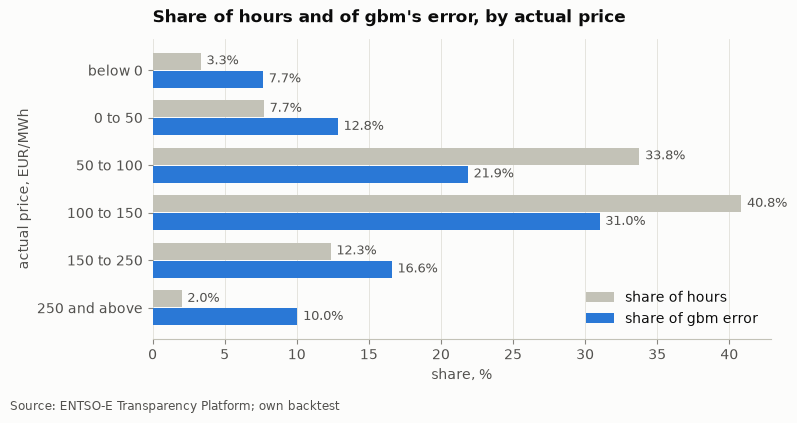

In [9]:
# Chart 3: share of hours and share of gbm's error in each price band.
fig, ax = plt.subplots(figsize=(8, 4.2))
band_positions = np.arange(len(BAND_LABELS))
bar_height = 0.36  # bar thickness; the two bars of a band sit just above and below its centre line
hours_bars = ax.barh(band_positions - bar_height / 2 - 0.01, regimes['share of hours (%)'], height=bar_height, color=BASELINE, label='share of hours')
error_bars = ax.barh(band_positions + bar_height / 2 + 0.01, regimes['share of gbm error (%)'], height=bar_height, color=MODEL_COLOURS['gbm'],
                     label='share of gbm error')

# Write each value at the end of its bar, in text colour (never the bar colour), to one decimal as in the table.
for bars in (hours_bars, error_bars):
    for bar in bars:
        value = bar.get_width()
        text = f'{value:.1f}%'
        ax.text(value + 0.4, bar.get_y() + bar.get_height() / 2, text, va='center', fontsize=9, color=INK_2)

ax.set_yticks(band_positions, BAND_LABELS)
ax.invert_yaxis()  # lowest prices at the top, reading downward like the table
ax.grid(axis='y', visible=False)
ax.grid(axis='x', visible=True)
ax.set_xlabel('share, %')
ax.set_ylabel('actual price, EUR/MWh')
ax.set_title("Share of hours and of gbm's error, by actual price")
ax.legend(loc='lower right')
save(fig, 'error_by_price_level.png', SOURCE_BACKTEST)

- `gbm` is better from 50 to 250 EUR/MWh: by 0.6 from 50 to 100 and 1.0 from 100 to 150, the bands holding 33.8% and 40.8% of hours, and by only 0.1 from 150 to 250.
- `linear` is better at both ends: by 2.1 below 0, 4.6 from 0 to 50 and 4.8 at 250 and above. The two offset, leaving the overall MAE at 21.18 against 21.30 EUR/MWh.

## 3. The ten worst days

A day's 24 prices clear in one auction and its 24 forecasts share one information set, so this section moves from hours to days: the worst 1% by `gbm`'s daily MAE, classed by the sign of its bias.

In [10]:
# The ten worst days, labelled by date (a holiday is marked) and classed by the sign of gbm's bias that day:
# under-forecast if the forecast was below the price on average, over-forecast if above it.
worst['error_type'] = np.where(worst['bias_gbm'] < 0, 'under-forecast', 'over-forecast')
day_labels = [day_label(day) + (' (holiday)' if worst.loc[day, 'holiday'] else '') for day in worst.index]

under_forecast_days = worst[worst['error_type'] == 'under-forecast']
over_forecast_days = worst[worst['error_type'] == 'over-forecast']
peak_reached = 100 * under_forecast_days['gbm_max'] / under_forecast_days['actual_max']
bias_share = 100 * -under_forecast_days['bias_gbm'] / under_forecast_days['mae_gbm']
print(f"{len(under_forecast_days)} under-forecast days and {len(over_forecast_days)} over-forecast. The weekly naive did worse than gbm on "
      f"{(worst['mae_naive'] > worst['mae_gbm']).sum()} of the {len(worst)} days.")
print(f"Under-forecast days: gbm's bias was {bias_share.min():.0f} to {bias_share.max():.0f}% of its MAE, and its highest "
      f"forecast reached {peak_reached.min():.0f} to {peak_reached.max():.0f}% of the actual peak.")
print(f"Mean MAE of gbm and of the papers' setup: under-forecast days {under_forecast_days['mae_gbm'].mean():.1f} and {under_forecast_days['mae_papers'].mean():.1f}, "
      f"over-forecast days {over_forecast_days['mae_gbm'].mean():.1f} and {over_forecast_days['mae_papers'].mean():.1f} EUR/MWh.")

misses = pd.DataFrame({
    'error type': worst['error_type'],
    'MAE gbm': worst['mae_gbm'],
    'MAE linear model': worst['mae_linear'],
    'MAE weekly naive': worst['mae_naive'],
    "MAE gbm, papers' setup": worst['mae_papers'],
    'bias gbm': worst['bias_gbm'],
}).set_axis(day_labels)
(misses.style.format('{:.0f}', subset=list(misses.columns[1:]))
 .pipe(captioned, "The worst 1% of days for gbm: MAE and bias over each day's hours, EUR/MWh"))

5 under-forecast days and 5 over-forecast. The weekly naive did worse than gbm on 8 of the 10 days.
Under-forecast days: gbm's bias was 78 to 99% of its MAE, and its highest forecast reached 38 to 60% of the actual peak.
Mean MAE of gbm and of the papers' setup: under-forecast days 83.2 and 73.9, over-forecast days 67.2 and 44.8 EUR/MWh.


,error type,MAE gbm,MAE linear model,MAE weekly naive,"MAE gbm, papers' setup",bias gbm
Mon 12 Jan 2026,under-forecast,113,116,117,89,-107
Tue 25 Nov 2025,under-forecast,91,100,147,85,-87
Sun 26 Apr 2026,over-forecast,75,71,99,69,44
Thu 22 Oct 2026,under-forecast,74,75,82,74,-62
Mon 14 Sep 2026,under-forecast,74,60,88,60,-73
Sat 25 Apr 2026,over-forecast,66,69,64,41,66
Wed 26 Nov 2025,over-forecast,66,47,37,42,65
Tue 13 Jan 2026,under-forecast,65,81,136,62,-51
Wed 5 Mar 2025,over-forecast,65,57,79,30,65
Thu 1 Jan 2026 (holiday),over-forecast,64,49,68,41,63


In [11]:
prices_and_wind = pd.DataFrame({
    ('Price', 'lowest'): worst['actual_min'],
    ('Price', 'highest'): worst['actual_max'],
    ('gbm forecast', 'lowest'): worst['gbm_min'],
    ('gbm forecast', 'highest'): worst['gbm_max'],
    ('Average price', 'vs day before'): worst['jump'],
    ("Day d's wind forecast", 'day average, GW'): worst['wind_gw'],
}).set_axis(day_labels)
(prices_and_wind.style.format('{:.0f}').format('{:.1f}', subset=[("Day d's wind forecast", 'day average, GW')])
 .pipe(captioned, "The same days: prices and the gbm forecast in EUR/MWh, and day d's wind forecast in GW"))

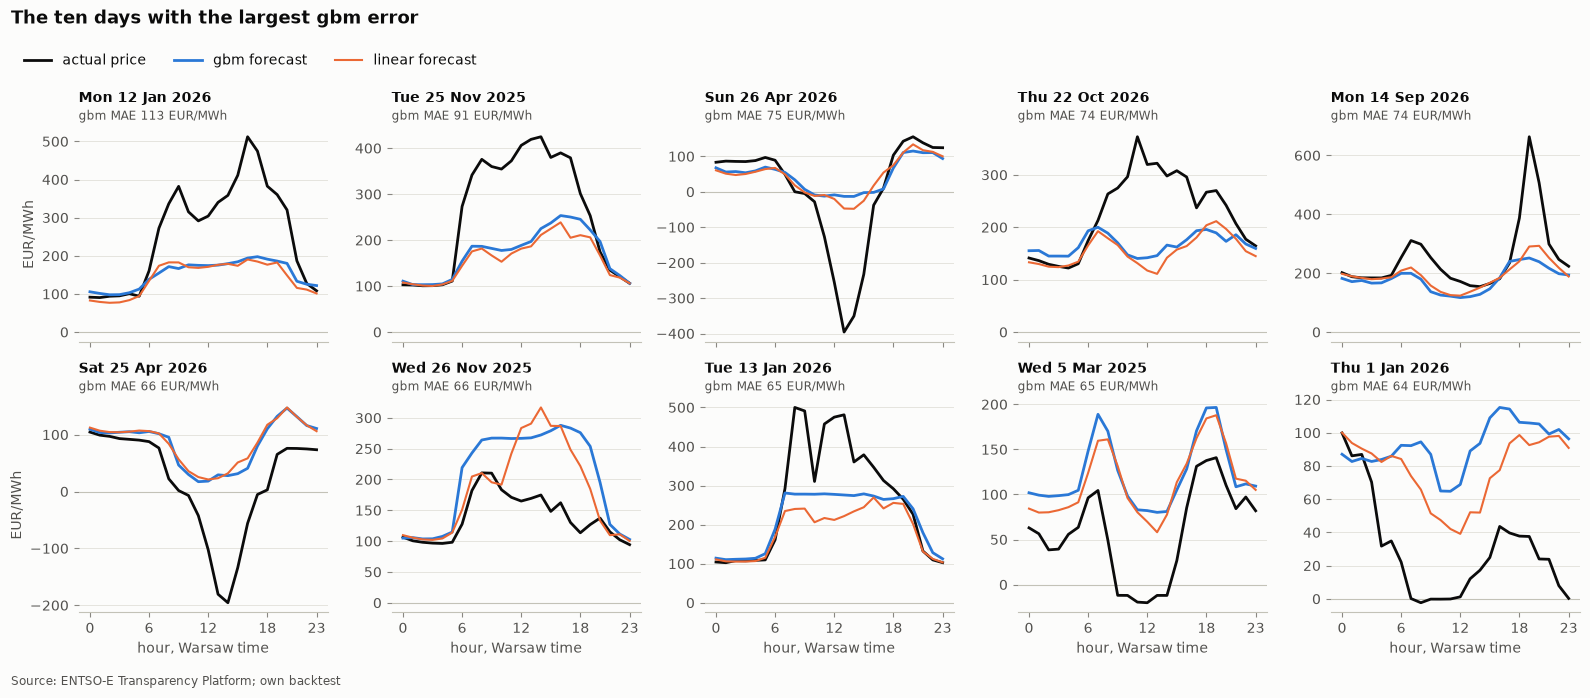

In [12]:
# Chart 4: the ten worst days, hour by hour. Each panel has its own price scale, because
# the days differ so much that a shared scale would flatten most of them.
fig, axes = plt.subplots(2, 5, figsize=(16, 7), sharex=True)
for ax, (day, row) in zip(axes.flat, worst.iterrows()):
    day_hours = hours[hours['day'] == day].sort_values('ts_utc')
    ax.axhline(0, color=BASELINE, lw=0.8)
    ax.plot(day_hours['hour'], day_hours['actual'], color=MODEL_COLOURS['actual'], lw=2, label='actual price')
    ax.plot(day_hours['hour'], day_hours['gbm'], color=MODEL_COLOURS['gbm'], lw=2, label='gbm forecast')
    ax.plot(day_hours['hour'], day_hours['linear'], color=MODEL_COLOURS['linear'], lw=1.5, label='linear forecast')
    ax.set_title(day_label(day), fontsize=10, pad=18)
    ax.text(0, 1.02, f"gbm MAE {row['mae_gbm']:.0f} EUR/MWh", transform=ax.transAxes, fontsize=8.5, color=INK_2,
            va='bottom', ha='left')
    ax.set_xticks([0, 6, 12, 18, 23])
for ax in axes[:, 0]:
    ax.set_ylabel('EUR/MWh')
for ax in axes[1]:
    ax.set_xlabel('hour, Warsaw time')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=3, bbox_to_anchor=(0.01, 0.93))
fig.text(0.01, 0.975, 'The ten days with the largest gbm error', fontsize=13, fontweight='bold', va='top')
save(fig, 'worst_days.png', SOURCE_BACKTEST, rect=(0, 0.03, 1, 0.88))

- Five under-forecast days, priced high all day: 12 and 13 January 2026, 25 November 2025, and 22 October and 14 September 2026. Four of them averaged 67 to 161 EUR/MWh above the previous day. Peaks reached 373 to 663 EUR/MWh, while `gbm`'s highest forecast reached 38 to 60% of the peak, and its bias was 78 to 99% of its MAE.
- Five over-forecast days: 25 and 26 April 2026, 1 January 2026 and 5 March 2025, each with strong wind (5.0 to 7.1 GW) and prices at or below zero, down to −396 EUR/MWh on 26 April; and 26 November 2025, the day after the high prices of 25 November, when the price fell back while `gbm`'s forecast rose to 288.
- With day d's renewables forecast, `gbm_papers` cut the MAE from 67.2 to 44.8 EUR/MWh on the over-forecast days, but only from 83.2 to 73.9 on the under-forecast days.
- The weekly naive did worse than `gbm` on eight of the ten.

## 4. Case study: 12 January 2026

The worst day, under-forecast all day. Residual load is the load forecast minus the renewables forecast: the demand left for dispatchable plants. Its daily maximum and minimum are the peak and minimum residual load. Top: prices and forecasts. Bottom: residual load as `gbm` saw it at 11:00 on Sunday, using the preceding delivery day's renewables forecast, and retrospectively with Monday's target-day forecast, due at 18:00 under the publication-deadline assumption. The latter was unavailable to the 11:00 model.

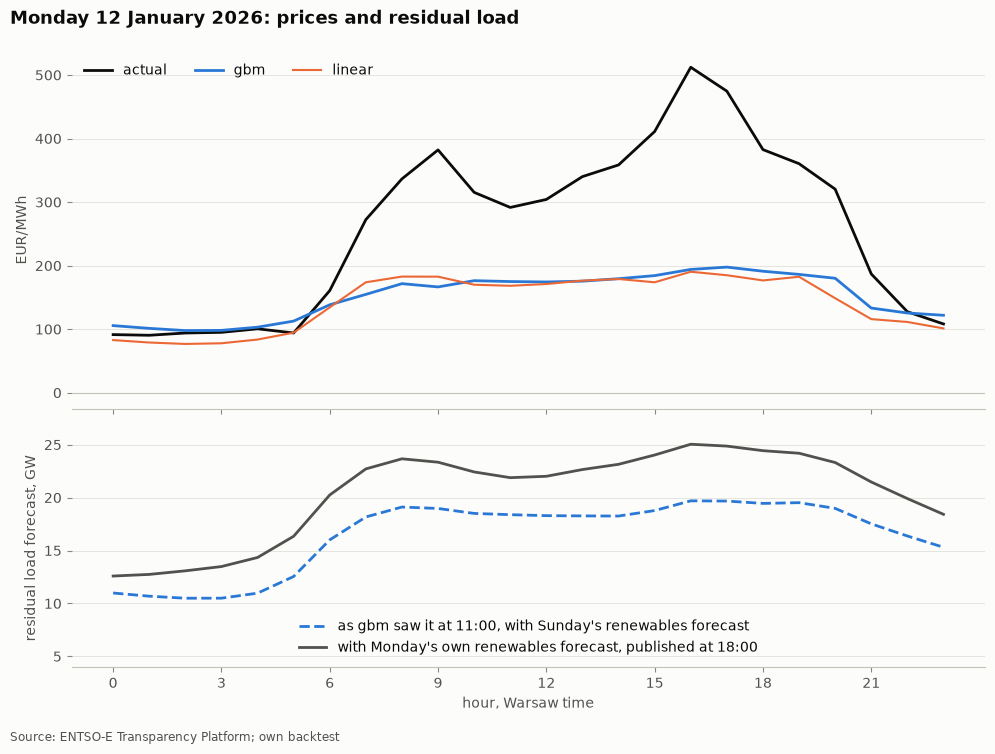

Price 90 to 512, gbm forecast 98 to 198 EUR/MWh; bias -106.9, MAE 112.5
Price peaks: 382 at 09:00 and 512 at 16:00. gbm's highest forecast before noon 176 at 10:00, 46% of the morning peak; after noon 198 at 17:00, 39% of the afternoon peak
gbm over-forecast in 7 of 24 hours: 00:00, 01:00, 02:00, 03:00, 04:00, 05:00, 23:00
Renewables forecast, day average: 6.4 GW for Sunday, which gbm saw; 2.5 GW for Monday
Peak residual load: 19.7 GW at 16:00 as gbm saw it, 25.0 GW at 16:00 with Monday's own forecast; peak load forecast 26.2 GW
Papers' setup: bias -82.0, MAE 89.3 EUR/MWh


In [13]:
DAY = worst.index[0]  # the worst day; replace with any date to inspect it
day_hours = hours[hours['day'] == DAY].sort_values('ts_utc')
day_before = DAY - pd.Timedelta(days=1)  # the renewables forecast gbm saw is the one for this day

fig, (top, bottom) = plt.subplots(2, 1, figsize=(10, 7.5), sharex=True, gridspec_kw={'height_ratios': [3, 2]})

top.axhline(0, color=BASELINE, lw=0.8)
for name, width in [('actual', 2), ('gbm', 2), ('linear', 1.5)]:
    top.plot(day_hours['hour'], day_hours[name], color=MODEL_COLOURS[name], lw=width, label=name)
top.set_ylabel('EUR/MWh')
top.legend(loc='upper left', ncol=3)

# Residual load using the preceding-day input available at 11:00, and retrospectively using the target-day forecast.
bottom.plot(day_hours['hour'], day_hours['residual_seen'] / MW_PER_GW, color=MODEL_COLOURS['gbm'], lw=2, ls='--',
            label=f"as gbm saw it at 11:00, with {day_before:%A}'s renewables forecast")
bottom.plot(day_hours['hour'], day_hours['residual_load_fcst'] / MW_PER_GW, color=INK_2, lw=2,
            label=f"with {DAY:%A}'s own renewables forecast, published at 18:00")
lowest_gw = min(day_hours['residual_seen'].min(), day_hours['residual_load_fcst'].min()) / MW_PER_GW
highest_gw = max(day_hours['residual_seen'].max(), day_hours['residual_load_fcst'].max()) / MW_PER_GW
bottom.set_ylim(lowest_gw - 0.45 * (highest_gw - lowest_gw), highest_gw + 0.1 * (highest_gw - lowest_gw))  # room for the legend below the lines
bottom.set_ylabel('residual load forecast, GW')
bottom.set_xlabel('hour, Warsaw time')
bottom.set_xticks(range(0, 24, 3))
bottom.legend(loc='lower center', ncol=1)

fig.text(0.01, 0.985, f"{DAY:%A} {DAY.day} {DAY:%B %Y}: prices and residual load", fontsize=13, fontweight='bold',
         va='top')
save(fig, 'worst_day_detail.png', SOURCE_BACKTEST, rect=(0, 0.03, 1, 0.95))
plt.show()

# The numbers behind the chart.
over_forecast_hours = day_hours.loc[day_hours['err_gbm'] > 0, 'hour']
morning, afternoon = day_hours[day_hours['hour'] < 12], day_hours[day_hours['hour'] >= 12]
print(f"Price {day_hours['actual'].min():.0f} to {day_hours['actual'].max():.0f}, gbm forecast {day_hours['gbm'].min():.0f} to "
      f"{day_hours['gbm'].max():.0f} EUR/MWh; bias {day_hours['err_gbm'].mean():.1f}, MAE {day_hours['abs_gbm'].mean():.1f}")
print(f"Price peaks: {morning['actual'].max():.0f} at {morning.loc[morning['actual'].idxmax(), 'hour']:02d}:00 and "
      f"{afternoon['actual'].max():.0f} at {afternoon.loc[afternoon['actual'].idxmax(), 'hour']:02d}:00. gbm's highest forecast before "
      f"noon {morning['gbm'].max():.0f} at {morning.loc[morning['gbm'].idxmax(), 'hour']:02d}:00, "
      f"{100 * morning['gbm'].max() / morning['actual'].max():.0f}% of the morning peak; after noon {afternoon['gbm'].max():.0f} at "
      f"{afternoon.loc[afternoon['gbm'].idxmax(), 'hour']:02d}:00, {100 * afternoon['gbm'].max() / afternoon['actual'].max():.0f}% of the afternoon peak")
print(f"gbm over-forecast in {len(over_forecast_hours)} of {len(day_hours)} hours: " + ', '.join(f'{hour:02d}:00' for hour in over_forecast_hours))
print(f"Renewables forecast, day average: {day_hours['renewables_fcst_lag_1d'].mean() / MW_PER_GW:.1f} GW for {day_before:%A}, which gbm saw; "
      f"{day_hours['renewables_fcst'].mean() / MW_PER_GW:.1f} GW for {DAY:%A}")
seen_hour, own_hour = day_hours.loc[day_hours['residual_seen'].idxmax()], day_hours.loc[day_hours['residual_load_fcst'].idxmax()]
print(f"Peak residual load: {seen_hour['residual_seen'] / MW_PER_GW:.1f} GW at {int(seen_hour['hour']):02d}:00 as "
      f"gbm saw it, {own_hour['residual_load_fcst'] / MW_PER_GW:.1f} GW at {int(own_hour['hour']):02d}:00 with {DAY:%A}'s own "
      f"forecast; peak load forecast {day_hours['load_fcst'].max() / MW_PER_GW:.1f} GW")
print(f"Papers' setup: bias {day_hours['err_gbm_papers'].mean():.1f}, MAE {day_hours['abs_gbm_papers'].mean():.1f} EUR/MWh")

- Prices peaked at 382 EUR/MWh at 09:00 and 512 at 16:00. `gbm` stayed between 98 and 198, peaking an hour after each price peak at 46% and 39% of its height.
- Bias −106.9 EUR/MWh against an MAE of 112.5: `gbm` over-forecast only from 23:00 to 06:00.
- `gbm`'s preceding-day input averaged 6.4 GW, compared with 2.5 GW in Monday's target-day forecast. Peak residual load was 19.7 GW using the input available at 11:00 and 25.0 GW in the retrospective target-day calculation. Peak load forecast: 26.2 GW.
- Using Monday's target-day forecast retrospectively narrows the under-forecast, but does not eliminate it: bias changes from −106.9 to −82.0 EUR/MWh. This case study does not identify the drivers of the remaining error.
- The day fell in a cold snap, with daytime temperatures down to −10°C and demand at or near record levels: reports citing PSE give about 27.5 to 27.6 GW net on 9 and 12 January, but differ on which day set the record ([enerad](https://enerad.pl/rekordowe-zapotrzebowanie-na-moc-w-kse-276-gw-netto-w-styczniu-2026/), [GLOBEnergia](https://globenergia.pl/polska-energetyka-z-nowym-rekordem-zapotrzebowania-na-moc/), [Spider's Web](https://spidersweb.pl/2026/02/energetyczne-rekordy-polski.html)).

## 5. Drivers: day-to-day renewables differences and extreme inputs

A miss can come from inputs the model lacked or from inputs that were unusual. The first check covers every day. It compares the target delivery day's renewables forecast with the forecast for the preceding delivery day, as day averages in GW. This cross-delivery-day difference is not a revision to a forecast for the same delivery day. Its association with daily bias is summarised by Spearman's rank correlation; the correlations are descriptive and do not establish causation or quantify error removable by better weather forecasts.

In [14]:
# Compare the forecast for the target delivery day with the forecast for the preceding delivery day.
# These are forecasts for different delivery days, not two vintages for the same day; values are day averages in GW.
renewables_by_day = hours.groupby('day')[['renewables_fcst_lag_1d', 'renewables_fcst']].mean() / MW_PER_GW
renewables_by_day['day_to_day_difference'] = renewables_by_day['renewables_fcst'] - renewables_by_day['renewables_fcst_lag_1d']
# The naive benchmarks have no renewables input: their correlation shows how far the link goes without one.
bias_labels = {'gbm': 'gbm', 'linear': 'linear model', 'gbm_papers': "papers' setup",
               'naive_similar_day': 'similar-day naive', 'naive_weekly': 'weekly naive'}
for model in bias_labels:
    renewables_by_day[f'bias_{model}'] = hours.groupby('day')[f'err_{model}'].mean()
print(f"Spearman's rank correlation of the day-to-day difference with the daily bias, over {len(renewables_by_day):,} days: " + ', '.join(
    f"{label} {renewables_by_day['day_to_day_difference'].corr(renewables_by_day[f'bias_{model}'], method='spearman'):.2f}"
    for model, label in bias_labels.items()))

# On the ten worst days: does the sign of gbm's bias match the sign of the day-to-day difference, and how large was the day-to-day difference
# against all days?
on_worst = renewables_by_day.loc[worst.index]
sign_matches = np.sign(on_worst['day_to_day_difference']) == np.sign(on_worst['bias_gbm'])
difference_percentile = 100 * renewables_by_day['day_to_day_difference'].abs().rank(pct=True)  # percentile of the day-to-day difference's size among all days
print(f"The sign of gbm's bias matches the sign of the day-to-day difference on {sign_matches.sum()} of {len(on_worst)} days; not on "
      + ', '.join(day_label(day, weekday=False) for day in on_worst.index[~sign_matches]))
large_difference_days = on_worst.index[difference_percentile[on_worst.index] >= 90]
print('Day-to-day difference among the largest 10% of all days: ' + '; '.join(
    f"{day_label(day, weekday=False)} ({on_worst.loc[day, 'day_to_day_difference']:+.1f} GW)" for day in large_difference_days))

seen_table = pd.DataFrame({
    'error type': worst['error_type'],
    'renewables gbm saw, GW': on_worst['renewables_fcst_lag_1d'],
    "renewables, day d's own, GW": on_worst['renewables_fcst'],
    'day-to-day difference, GW': on_worst['day_to_day_difference'],
    'bias gbm': on_worst['bias_gbm'],
    "bias papers' setup": on_worst['bias_gbm_papers'],
}).set_axis(day_labels)
(seen_table.style.format('{:.1f}', subset=['renewables gbm saw, GW', "renewables, day d's own, GW"])
 .format('{:+.1f}', subset=['day-to-day difference, GW']).format(whole, subset=['bias gbm', "bias papers' setup"])
 .pipe(captioned, "The ten worst days: the renewables forecast gbm saw and day d's own, day averages in GW, "
              "and the bias of gbm and of the papers' setup, EUR/MWh"))

Spearman's rank correlation of the day-to-day difference with the daily bias, over 1,028 days: gbm 0.59, linear model 0.56, papers' setup 0.19, similar-day naive 0.50, weekly naive 0.27
The sign of gbm's bias matches the sign of the day-to-day difference on 9 of 10 days; not on 26 Apr 2026
Day-to-day difference among the largest 10% of all days: 12 Jan 2026 (-4.0 GW); 22 Oct 2026 (-3.4 GW); 25 Apr 2026 (+4.1 GW)


,error type,"renewables gbm saw, GW","renewables, day d's own, GW","day-to-day difference, GW",bias gbm,bias papers' setup
Mon 12 Jan 2026,under-forecast,6.4,2.5,-4.0,-107,-82
Tue 25 Nov 2025,under-forecast,3.1,1.8,-1.3,-87,-77
Sun 26 Apr 2026,over-forecast,10.6,9.5,-1.1,44,48
Thu 22 Oct 2026,under-forecast,8.2,4.7,-3.4,-62,-68
Mon 14 Sep 2026,under-forecast,3.5,3.0,-0.4,-73,-59
Sat 25 Apr 2026,over-forecast,6.5,10.6,+4.1,66,41
Wed 26 Nov 2025,over-forecast,1.8,4.2,+2.4,65,42
Tue 13 Jan 2026,under-forecast,2.5,2.0,-0.4,-51,-42
Wed 5 Mar 2025,over-forecast,8.9,10.0,+1.1,65,30
Thu 1 Jan 2026 (holiday),over-forecast,4.6,7.0,+2.4,63,41


- Daily bias has a positive association with the cross-delivery-day difference: Spearman correlation is 0.59 for `gbm` and 0.56 for `linear`, compared with 0.19 for `gbm_papers`, which uses the target-day forecast.
- The association also appears for models without a renewables input: 0.50 for the similar-day naive and 0.27 for the weekly naive. The similar-day naive's positive association cautions against attributing the relationship to the renewables input or interpreting it causally.
- On nine of the ten worst days the bias had the same sign as the difference between forecasts for consecutive delivery days. The exception, 26 April 2026, was over-forecast by `gbm_papers` too.
- The day-to-day difference was among the largest 10% on 12 January (−4.0 GW), 25 April (+4.1) and 22 October 2026 (−3.4), but only −0.4 GW on 13 January and 14 September.

Retrospective substitution of the target-day forecast reduces but does not eliminate the under-forecast days' MAE: `gbm_papers` averages 73.9 EUR/MWh, against `gbm`'s 83.2. This analysis does not identify the drivers of the remaining error. The second check ranks each worst day's inputs, on day d's forecasts, within a reference window: the days within 30 days of it of the same type (working day, or weekend and holiday). The inputs are mean wind, peak load, and peak and minimum residual load. An input beyond the 5th or 95th percentile counts as extreme.

In [15]:
# For each worst day: where the target delivery day's forecasts fall in its reference window, the days within 30 days of it,
# before or after, of the same type (working day, or weekend and holiday), without the day itself.
# Each percentile is the share of reference days with a lower value: 0 is the lowest, 100 the highest.
per_day = hours.groupby('day').agg(
    wind=('wind_fcst', 'mean'), peak_load=('load_fcst', 'max'),
    residual_max=('residual_load_fcst', 'max'), residual_min=('residual_load_fcst', 'min'),
) / MW_PER_GW
per_day['off'] = (per_day.index.dayofweek >= 5) | daily['holiday'].reindex(per_day.index).to_numpy()


def reference_days(day):
    # The reference window defined above. Section 6 uses the same function, so the rule cannot drift.
    window = abs(per_day.index - day) <= pd.Timedelta(days=30)
    same_type = (per_day['off'] == per_day.loc[day, 'off']).to_numpy()
    return per_day[window & same_type].drop(day)


INPUT_NAMES = {'wind': 'wind', 'peak_load': 'peak load', 'residual_max': 'peak residual load', 'residual_min': 'minimum residual load'}
rows = []
for day in worst.index:
    reference = reference_days(day)
    row = {('error type', ''): worst.loc[day, 'error_type'], ('reference days', ''): len(reference)}
    for column, name in INPUT_NAMES.items():
        row[(name, 'GW')] = per_day.loc[day, column]
        row[(name, 'percentile')] = 100 * (reference[column] < per_day.loc[day, column]).mean()
    rows.append(pd.Series(row, name=day))
inputs = pd.DataFrame(rows)

# Which inputs are extreme (beyond the 5th or 95th percentile), and which miss that cut-off by a single
# reference day: with n reference days, one day moves a percentile by 100/n points.
percentile_columns = [(name, 'percentile') for name in INPUT_NAMES.values()]
for day in inputs.index:
    reference_count = inputs.loc[day, ('reference days', '')]
    percentiles = {name: inputs.loc[day, (name, 'percentile')] for name in INPUT_NAMES.values()}
    extreme_inputs = [name for name, percentile in percentiles.items() if not 5 <= percentile <= 95]
    one_day_short = [name for name, percentile in percentiles.items() if name not in extreme_inputs and (percentile + 100 / reference_count > 95 or percentile - 100 / reference_count < 5)]
    print(f"{day_label(day, weekday=False)} ({inputs.loc[day, ('error type', '')]}): extreme {', '.join(extreme_inputs) or 'none'}"
          + (f"; one reference day short: {', '.join(one_day_short)}" if one_day_short else ''))
has_extreme = ((inputs[percentile_columns] > 95) | (inputs[percentile_columns] < 5)).any(axis=1)
print(f"{has_extreme.sum()} of {len(inputs)} days have at least one extreme input")

# A window cut short by the end of the data, and how peak load moves with the date across the same window in each
# year: when load rises through the season, the last day of a one-sided window ranks near the top.
last_day = per_day.index.max()
for day in inputs.index[inputs.index + pd.Timedelta(days=30) > last_day]:
    reference = reference_days(day)
    print(f"{day_label(day, weekday=False)}: the data ends on {day_label(last_day, weekday=False)}, so "
          f"{(reference.index < day).sum()} reference days come before it and {(reference.index > day).sum()} after")
    trend_by_year = {}
    for year in sorted(set(per_day.index.year)):
        centre = day.replace(year=year)
        same_window = per_day[(abs(per_day.index - centre) <= pd.Timedelta(days=30)) & (per_day['off'] == per_day.loc[day, 'off'])]
        same_window = same_window.drop(centre, errors='ignore')
        trend_by_year[year] = pd.Series(np.arange(len(same_window)), index=same_window.index).corr(same_window['peak_load'], method='spearman')
    print('  rank correlation of peak load with the date across the same window: '
          + ', '.join(f'{year} {correlation:.2f}' for year, correlation in trend_by_year.items()))

gw_columns = [(name, 'GW') for name in INPUT_NAMES.values()]
(inputs.set_axis(day_labels).style.format('{:.1f}', subset=gw_columns + percentile_columns)
 .pipe(captioned, "Day d's forecasts on the ten worst days: mean wind, peak load, and peak and minimum residual load, in GW, "
              "with each one's percentile in the reference window"))

12 Jan 2026 (under-forecast): extreme none; one reference day short: peak residual load
25 Nov 2025 (under-forecast): extreme peak residual load, minimum residual load; one reference day short: peak load
26 Apr 2026 (over-forecast): extreme none
22 Oct 2026 (under-forecast): extreme peak load
14 Sep 2026 (under-forecast): extreme wind, minimum residual load
25 Apr 2026 (over-forecast): extreme none; one reference day short: wind
26 Nov 2025 (over-forecast): extreme peak load
13 Jan 2026 (under-forecast): extreme none; one reference day short: peak load
5 Mar 2025 (over-forecast): extreme wind, peak residual load, minimum residual load
1 Jan 2026 (over-forecast): extreme peak load, minimum residual load; one reference day short: wind, peak residual load
6 of 10 days have at least one extreme input
22 Oct 2026: the data ends on 24 Oct 2026, so 22 reference days come before it and 1 after
  rank correlation of peak load with the date across the same window: 2024 0.92, 2025 0.80, 2026 0.93

- Six of the ten days had at least one extreme input. 12 and 13 January had none, yet peaked at 512 and 500 EUR/MWh.
- Under-forecast days: 14 September had wind below the 5th percentile (0.7 GW) and the highest minimum residual load of its window; 25 November had peak and minimum residual load at the 97.5th and 100th percentiles; 22 October had the highest peak load.
- Over-forecast days: 5 March 2025 had the strongest wind of its window and both residual-load measures below the 5th percentile; 1 January 2026 had the lowest peak load and a minimum residual load below the 5th percentile; 26 November 2025 had the highest peak load. 25 and 26 April had none.
- Three of the four days without an extreme input missed the cut-off by one reference day: 12 January's peak residual load at the 94.6th percentile of 37 days, 13 January's peak load at the 94.7th of 38, and 25 April's wind at the 94.7th of 19.
- 22 October's window is one-sided, with 22 days before it and 1 after, and working-day peak load rises with the date at that time of year (rank correlation 0.92, 0.80 and 0.93 in 2024 to 2026), so its 100th percentile partly reflects its position.

## 6. Analogue days

An extreme input does not show that the input explains the price. This section compares each under-forecast day with its five analogue days: the days in its reference window whose peak residual load came closest, on day d's forecasts. If the analogues priced as high, the information was in the inputs; if not, the price came from something the inputs miss. Matching on peak residual load targets the daily price peak, since that hour calls on the most expensive plants. The analogues are selected ex post using the target delivery day's forecast, which was unavailable to the 11:00 models under the publication-deadline assumption. `gbm_papers`, which uses that input, is therefore the model judged here.

In [16]:
# Each under-forecast day against its analogue days: the five reference days (section 5) whose peak residual load
# came closest to the day's own. They are selected ex post using the target-day forecast, unavailable to the 11:00
# models under the deadline assumption, so the model columns use the papers' setup.
peak_residual_hour = hours.loc[hours.groupby('day')['residual_load_fcst'].idxmax()].set_index('day')
per_day['peak'] = daily['actual_max']
per_day['papers_peak'] = hours.groupby('day')['gbm_papers'].max()
per_day['residual_mean'] = hours.groupby('day')['residual_load_fcst'].mean() / MW_PER_GW
per_day['gbm_err_peak'] = peak_residual_hour['err_gbm']
per_day['papers_err_peak'] = peak_residual_hour['err_gbm_papers']


def analogue_days(day, count=5):
    reference = reference_days(day)
    return reference.loc[(reference['residual_max'] - per_day.loc[day, 'residual_max']).abs().nsmallest(count).index]


UNDER_FORECAST_DAYS = list(under_forecast_days.index)
rows = []
for day in UNDER_FORECAST_DAYS:
    analogues, own = analogue_days(day), per_day.loc[day]
    rows.append(pd.Series({
        ('Peak price', 'the day'): own['peak'],
        ('Peak price', 'analogues, median'): analogues['peak'].median(),
        ('Peak price', 'analogues, highest'): analogues['peak'].max(),
        ('Peak price', 'day ÷ analogue median'): own['peak'] / analogues['peak'].median(),
        ("Papers' setup, highest forecast", 'the day'): own['papers_peak'],
        ("Papers' setup, highest forecast", 'analogues, median'): analogues['papers_peak'].median(),
        ("Papers' setup, highest forecast", 'day ÷ analogue median'): own['papers_peak'] / analogues['papers_peak'].median(),
        ("Papers' setup, error at peak residual load", 'analogues, median'): analogues['papers_err_peak'].median(),
    }, name=day_label(day)))
analogue_table = pd.DataFrame(rows)

# Days whose peak some analogue matched or beat, and whether that analogue is itself one of the ten worst days.
above_all = sum(per_day.loc[day, 'peak'] > analogue_days(day)['peak'].max() for day in UNDER_FORECAST_DAYS)
print(f"The day's peak price was above all five analogues on {above_all} of {len(UNDER_FORECAST_DAYS)} days. The others:")
for day in UNDER_FORECAST_DAYS:
    analogues = analogue_days(day)
    higher = analogues[analogues['peak'] >= per_day.loc[day, 'peak']]
    for other, peak in higher['peak'].items():
        print(f"  {day_label(day, weekday=False)} ({per_day.loc[day, 'peak']:.0f}): analogue "
              f"{day_label(other, weekday=False)} reached {peak:.0f}" + (', one of the ten worst days' if other in worst.index else ''))
pairs = sorted({tuple(sorted((a, b))) for a in UNDER_FORECAST_DAYS for b in analogue_days(a).index
                if b in UNDER_FORECAST_DAYS and a in analogue_days(b).index})
print("Under-forecast days that are each other's analogues: "
      + ('; '.join(f'{day_label(a, weekday=False)} and {day_label(b, weekday=False)}' for a, b in pairs) or 'none'))
ratio_columns = [c for c in analogue_table.columns if c[1] == 'day ÷ analogue median']
(analogue_table.style.format(whole).format('{:.1f}', subset=ratio_columns)
 .pipe(captioned, "Each under-forecast day against its five analogue days: prices, and the papers' setup's forecasts and "
              "errors, in EUR/MWh"))

The day's peak price was above all five analogues on 3 of 5 days. The others:
  22 Oct 2026 (373): analogue 23 Sep 2026 reached 373
  22 Oct 2026 (373): analogue 6 Oct 2026 reached 378
  13 Jan 2026 (500): analogue 12 Jan 2026 reached 512, one of the ten worst days
Under-forecast days that are each other's analogues: 12 Jan 2026 and 13 Jan 2026


- The under-forecast days peaked at 1.2 to 2.1 times their analogues' median peak of 214 to 348 EUR/MWh, and three of the five above all five analogues. On 22 October two analogues matched or beat the day's 373 EUR/MWh, at 373 and 378; on 13 January the only higher analogue was 12 January, at 512.
- `gbm_papers` did not single the days out: its highest forecast was 0.8 to 1.2 times its highest forecast for their analogues. A day's highest forecast sits below its price peak even when the forecast is sound.
- `gbm_papers` also under-forecast the analogues at peak residual load, by a median of 49 to 74 EUR/MWh in four of the five windows; around 25 November 2025 it over-forecast by 25.

Rank correlation of the reference days' peak price with residual load, across the 5 windows: peak residual load 0.57 to 0.77, daily average 0.37 to 0.66
Price peak more than an hour from peak residual load: 25 Nov 2025 (peak 14:00, peak residual load 08:00); 22 Oct 2026 (peak 11:00, peak residual load 18:00)


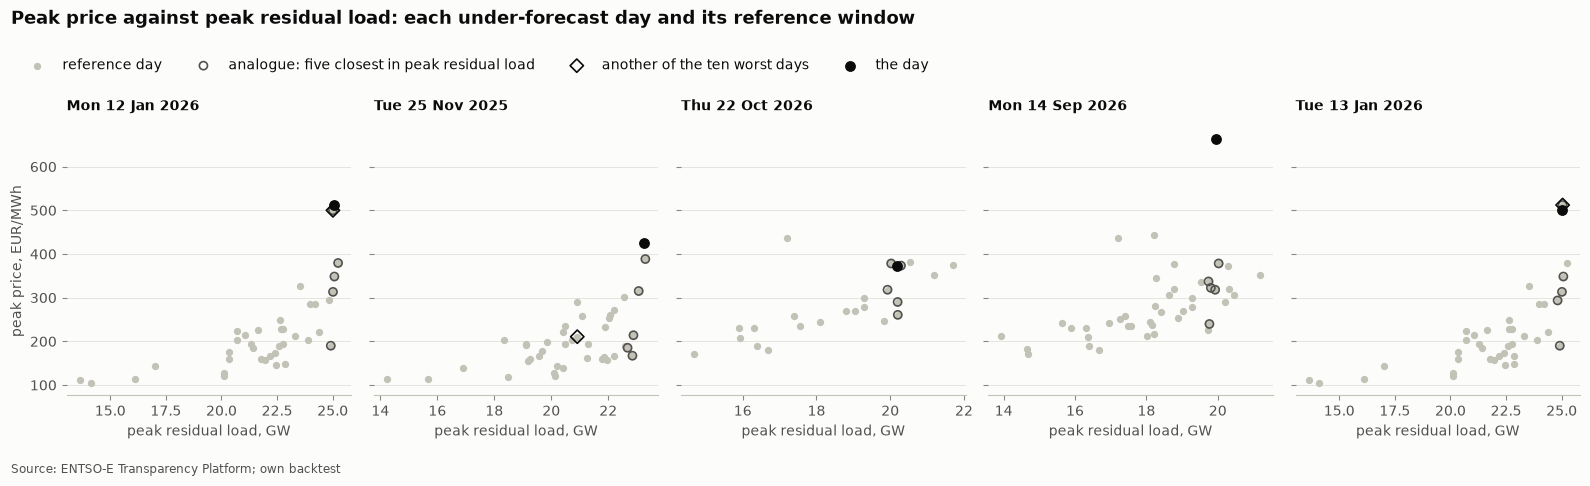

In [17]:
# Chart 6: each under-forecast day and its reference window, peak price against peak residual load.
rank_correlations = []
for day in UNDER_FORECAST_DAYS:
    reference = reference_days(day)
    rank_correlations.append({'peak residual load': reference['residual_max'].corr(reference['peak'], method='spearman'),
                'daily average': reference['residual_mean'].corr(reference['peak'], method='spearman')})
rank_correlations = pd.DataFrame(rank_correlations)
print(f"Rank correlation of the reference days' peak price with residual load, across the {len(UNDER_FORECAST_DAYS)} windows: "
      f"peak residual load {rank_correlations['peak residual load'].min():.2f} to {rank_correlations['peak residual load'].max():.2f}, "
      f"daily average {rank_correlations['daily average'].min():.2f} to {rank_correlations['daily average'].max():.2f}")
peak_hour = hours.loc[hours.groupby('day')['actual'].idxmax()].set_index('day')['hour']
peak_apart_days = [day for day in UNDER_FORECAST_DAYS if abs(peak_hour[day] - peak_residual_hour.loc[day, 'hour']) > 1]
print('Price peak more than an hour from peak residual load: ' + '; '.join(
    f"{day_label(day, weekday=False)} (peak {peak_hour[day]:02d}:00, peak residual load {peak_residual_hour.loc[day, 'hour']:02d}:00)"
    for day in peak_apart_days))

fig, axes = plt.subplots(1, len(UNDER_FORECAST_DAYS), figsize=(16, 4.8), sharey=True)
for ax, day in zip(axes, UNDER_FORECAST_DAYS):
    reference, analogues = reference_days(day), analogue_days(day)
    worst_in_window = reference[reference.index.isin(worst.index)]  # another of the ten worst days in the same window
    ax.scatter(reference['residual_max'], reference['peak'], s=18, color=BASELINE, label='reference day', zorder=2)
    ax.scatter(analogues['residual_max'], analogues['peak'], s=34, facecolor='none', edgecolor=INK_2, lw=1.2,
               label='analogue: five closest in peak residual load', zorder=3)
    ax.scatter(worst_in_window['residual_max'], worst_in_window['peak'], s=46, marker='D', facecolor='none', edgecolor=INK, lw=1.2,
               label='another of the ten worst days', zorder=3)
    ax.scatter([per_day.loc[day, 'residual_max']], [per_day.loc[day, 'peak']], s=46, color=MODEL_COLOURS['actual'], label='the day',
               zorder=4)
    ax.set_title(day_label(day), fontsize=10)
axes[0].set_ylabel('peak price, EUR/MWh')
for ax in axes:
    ax.set_xlabel('peak residual load, GW')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left', ncol=4, bbox_to_anchor=(0.01, 0.9))
fig.text(0.01, 0.975, 'Peak price against peak residual load: each under-forecast day and its reference window',
         fontsize=13, fontweight='bold', va='top')
save(fig, 'analogue_days.png', SOURCE_BACKTEST, rect=(0, 0.05, 1, 0.82))

- Within each window the peak price rises with peak residual load, with a rank correlation of 0.57 to 0.77, more than with the daily average (0.37 to 0.66), which supports matching on the peak.
- On 25 November 2025 and 22 October 2026 the price peaked more than an hour from peak residual load (14:00 against 08:00, 11:00 against 18:00), so their analogues are a weaker guide.

### Robustness by year

To test the under-forecast at tight hours across the whole backtest, the table takes the days in the top quarter and top 5% of their window by peak residual load, without the ten worst days, and gives the median error at that hour by year. The analysis contrasts ex-ante selection using residual load available at 11:00 (`gbm` and `linear`) with ex-post selection using the target-day forecast (`gbm_papers`). `gbm` is also evaluated on the ex-post-selected days to show the effect of selecting days with information unavailable at issue time.

In [18]:
# Robustness by year. Ex-ante selection uses residual load available at 11:00 for gbm and linear; ex-post
# selection uses the target delivery day's renewables forecast for the papers' setup. gbm is also evaluated on
# the ex-post-selected days to show the selection effect. Each day is ranked within its reference window; the ten
# worst days are left out.
peak_residual_hour_seen = hours.loc[hours.groupby('day')['residual_seen'].idxmax()].set_index('day')  # as gbm saw it
per_day['residual_max_seen'] = peak_residual_hour_seen['residual_seen'] / MW_PER_GW
per_day['gbm_err_seen'] = peak_residual_hour_seen['err_gbm']
per_day['linear_err_seen'] = peak_residual_hour_seen['err_linear']


def rank_in_window(column):
    # Each day's percentile within its own reference days.
    return pd.Series({day: 100 * (reference_days(day)[column] < per_day.loc[day, column]).mean() for day in per_day.index})


def median_by_year(days, column):
    return days.groupby(days.index.year)[column].median()


def count_by_year(days):
    return days.groupby(days.index.year).size()


other_days = per_day.drop(worst.index).assign(rank_seen=rank_in_window('residual_max_seen'), rank_own=rank_in_window('residual_max'))
quarter_seen, quarter_own = other_days[other_days['rank_seen'] >= 75], other_days[other_days['rank_own'] >= 75]
top5_seen, top5_own = other_days[other_days['rank_seen'] >= 95], other_days[other_days['rank_own'] >= 95]
robustness_by_year = pd.DataFrame({
    ('top quarter', 'gbm, tight as seen at 11:00'): median_by_year(quarter_seen, 'gbm_err_seen'),
    ('top quarter', "papers' setup, tight on day d's forecast"): median_by_year(quarter_own, 'papers_err_peak'),
    ('top quarter', "gbm, tight on day d's forecast"): median_by_year(quarter_own, 'gbm_err_peak'),
    ('top 5%', 'gbm, tight as seen at 11:00'): median_by_year(top5_seen, 'gbm_err_seen'),
    ('top 5%', 'linear, tight as seen at 11:00'): median_by_year(top5_seen, 'linear_err_seen'),
    ('top 5%', "papers' setup, tight on day d's forecast"): median_by_year(top5_own, 'papers_err_peak'),
    ('top 5%', 'days tight as seen at 11:00'): count_by_year(top5_seen),
    ('top 5%', "days tight on day d's forecast"): count_by_year(top5_own),
}).T.rename_axis(columns='year')

# On the days picked by day d's forecast, how did that forecast compare with the one gbm saw?
print(f"Median cross-delivery-day difference (section 5), top quarter: {renewables_by_day.loc[quarter_own.index, 'day_to_day_difference'].median():+.1f} GW "
      f"on ex-post-selected days, {renewables_by_day.loc[quarter_seen.index, 'day_to_day_difference'].median():+.1f} GW on ex-ante-selected days "
      f"as seen at 11:00")
(robustness_by_year.style.format(whole)
 .pipe(captioned, 'Median error at peak residual load on tight days (forecast minus price, EUR/MWh) and number of days, '
              'by year, without the ten worst days'))

Median cross-delivery-day difference (section 5), top quarter: -0.7 GW on ex-post-selected days, +0.4 GW on ex-ante-selected days as seen at 11:00


- With ex-ante selection based on information available at 11:00, `gbm` shows no systematic under-forecast: median error −5, 0 and −7 EUR/MWh in the top quarter in 2024 to 2026, and 0, 4 and 0 in the top 5%.
- With ex-post selection using the target-day forecast, its median error is −13, −27 and −28. Those days had a median cross-delivery-day difference of −0.7 GW. This is a selection effect from using information unavailable at 11:00, not evidence of model bias under the ex-ante selection.
- `gbm_papers` under-forecast the top 5% in 2026, by a median of 43 EUR/MWh on 17 days, against 4 and 9 in 2024 and 2025; in the top quarter it stayed within 5 EUR/MWh of zero (−4, −5 and −2).
- `linear` over-forecast the top 5% in 2025 and 2026 (median +22 and +33 EUR/MWh, against −2 in 2024), so neither 11:00 model under-forecast tight days in general.
- Hypothesis, not tested: in 2026 the supply curve steepened at high residual load beyond what the 365-day training window had seen. Notebook 01 is consistent with it: the 2026 median price rose from 166 EUR/MWh at 22 to 23 GW to 280 at 24 to 25 GW, against 158 and 187 in 2023, and in 2025 no band above 23 GW held the 30 hours needed to draw it (section 5 there). The main models see no fuel or carbon prices, and the carbon variants brought no significant gain (README, Variants).

## 7. Contemporaneous zonal price differences

This section compares Poland, Germany-Luxembourg and Czechia at the same delivery timestamp. The join uses the UTC start of each hourly interval, then displays it on the Warsaw clock; CET and CEST distinguish the repeated 02:00 hour when the clocks go back. From October 2025, each hourly price is the mean of that hour's four quarter-hour prices.

The table reports the three prices at every tied Polish daily maximum in the common backtest sample, and the largest observed positive Polish price spread against each neighbour. Coverage distinguishes the common backtest sample from the underlying hourly market data, so a forecast gap cannot be mistaken for a missing market price. A contemporaneous price spread establishes price separation in that auction interval. It does not show the flows, available capacity, outages or other cause of the difference.

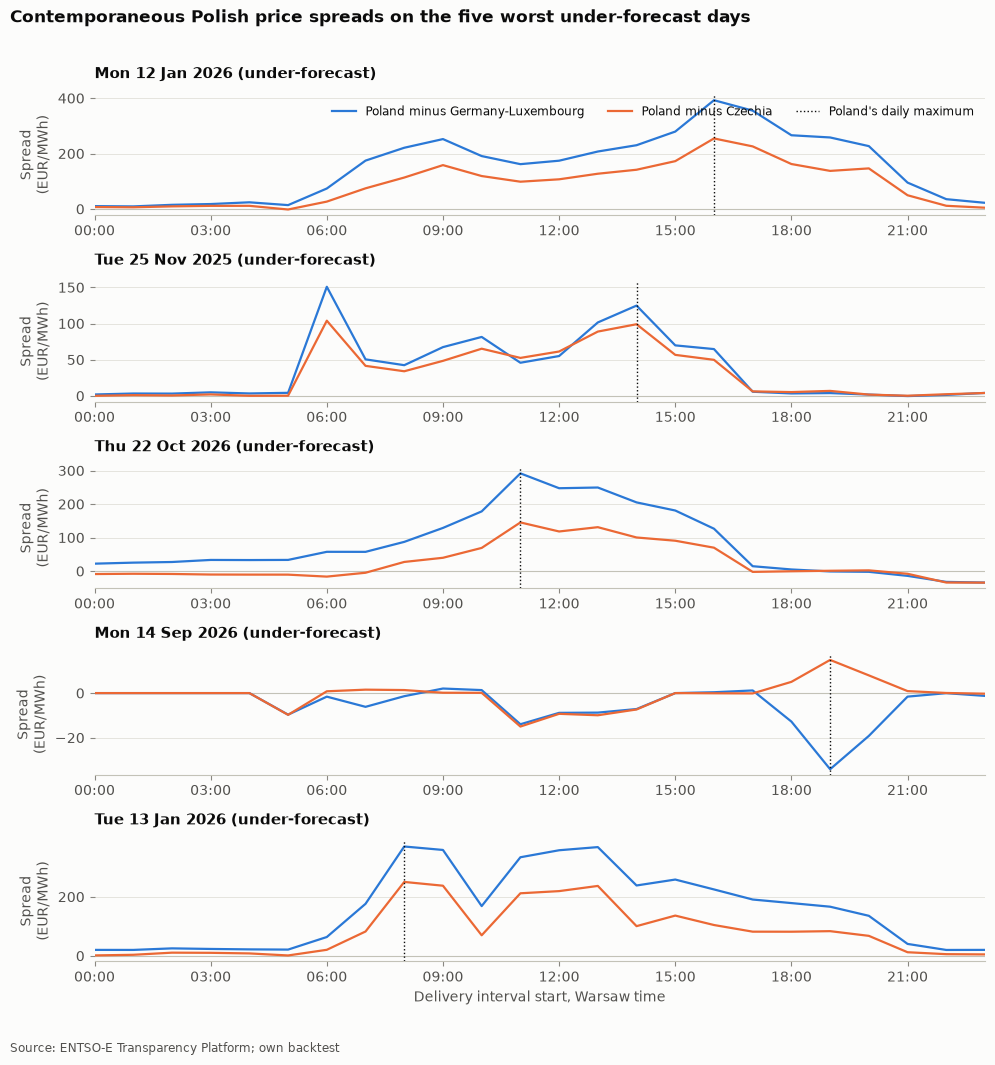

In [19]:
# Join prices by the UTC start of each delivery hour. hours is the common backtest sample that selected
# these days; the left join preserves its timestamps and leaves a neighbour's missing price visible.
zone_prices = (hours[['ts_utc', 'day', 'actual']].rename(columns={'actual': 'price_pl'})
               .merge(hourly[['ts_utc', 'price_de_lu', 'price_cz']], on='ts_utc', how='left', validate='one_to_one'))
zone_prices['spread_pl_de'] = zone_prices['price_pl'] - zone_prices['price_de_lu']
zone_prices['spread_pl_cz'] = zone_prices['price_pl'] - zone_prices['price_cz']
zone_by_time = zone_prices.set_index('ts_utc').sort_index()

# Underlying hourly market-data coverage is separate from the common backtest sample. This makes a model's
# missing forecast distinguishable from a missing market observation.
market_by_time = (hourly[['ts_utc', 'price', 'price_de_lu', 'price_cz']]
                  .rename(columns={'price': 'price_pl'}).set_index('ts_utc').sort_index())
PRICE_COLUMNS = ['price_pl', 'price_de_lu', 'price_cz']


def maximum_rows(frame, column, positive_only=False):
    observed = frame.dropna(subset=[column])
    if positive_only:
        observed = observed[observed[column] > 0]
    if observed.empty:
        return observed
    return observed[observed[column] == observed[column].max()]


def local_time_labels(index):
    local = index.tz_convert(LOCAL_TZ)
    clock = pd.Series(local.strftime('%H:%M'), index=index)
    # Show the zone only when the Warsaw clock repeats, keeping ordinary-day labels compact.
    return local.strftime('%H:%M %Z') if clock.duplicated().any() else clock.to_numpy()


def report_times(rows):
    return ' / '.join(rows.index.tz_convert(LOCAL_TZ).strftime('%H:%M %Z')) if not rows.empty else '—'


def report_values(rows, column):
    return ' / '.join('—' if pd.isna(value) else f'{value:.1f}' for value in rows[column]) if not rows.empty else '—'


def coverage(frame):
    return '/'.join(str(int(frame[column].notna().sum())) for column in PRICE_COLUMNS)


def positive_spread(frame, column):
    widest = maximum_rows(frame, column, positive_only=True)
    if not widest.empty:
        return report_values(widest, column), report_times(widest)
    observed = frame.dropna(subset=[column])
    if observed.empty:
        return 'no data', '—'
    highest = maximum_rows(frame, column)
    return f'none (highest {report_values(highest, column)})', report_times(highest)


rows = []
for day in worst.index:
    expected = delivery_index(day.date())  # 23, 24 or 25 Warsaw delivery hours, represented in UTC
    common = zone_by_time.reindex(expected)
    market = market_by_time.reindex(expected)
    peak = maximum_rows(common, 'price_pl')  # retain every tied Polish maximum rather than choosing one
    de_spread, de_time = positive_spread(common, 'spread_pl_de')
    cz_spread, cz_time = positive_spread(common, 'spread_pl_cz')
    rows.append({
        ('', 'error type'): worst.loc[day, 'error_type'],
        ('Coverage, hours', 'expected'): len(expected),
        ('Coverage, hours', 'common sample PL / DE / CZ'): coverage(common),
        ('Coverage, hours', 'market data PL / DE / CZ'): coverage(market),
        ("At Poland's maximum", 'delivery hour, Warsaw time'): report_times(peak),
        ("At Poland's maximum", 'Poland'): report_values(peak, 'price_pl'),
        ("At Poland's maximum", 'Germany-Luxembourg'): report_values(peak, 'price_de_lu'),
        ("At Poland's maximum", 'Czechia'): report_values(peak, 'price_cz'),
        ("At Poland's maximum", 'Poland minus Germany'): report_values(peak, 'spread_pl_de'),
        ("At Poland's maximum", 'Poland minus Czechia'): report_values(peak, 'spread_pl_cz'),
        ('Largest positive Polish spread', 'vs Germany-Luxembourg, EUR/MWh'): de_spread,
        ('Largest positive Polish spread', 'delivery hour, Warsaw time (DE-LU)'): de_time,
        ('Largest positive Polish spread', 'vs Czechia, EUR/MWh'): cz_spread,
        ('Largest positive Polish spread', 'delivery hour, Warsaw time (CZ)'): cz_time,
    })

neighbour_table = pd.DataFrame(rows, index=worst.index).set_axis(day_labels)
neighbour_table.columns = pd.MultiIndex.from_tuples(neighbour_table.columns)
display(neighbour_table.style
        .pipe(captioned, 'Contemporaneous day-ahead prices and Polish price spreads on the ten worst days. Prices and spreads are EUR/MWh. Coverage is observed intervals in Poland / Germany-Luxembourg / Czechia; the common sample is the scoreable backtest sample, while market data is the underlying hourly table. Since October 2025, each hourly price is the mean of four quarter-hour prices.'))

# Plot spreads by interval rather than clock hour, so a 23- or 25-hour delivery day keeps every observation
# and the repeated autumn 02:00 remains distinct.
under_days = list(under_forecast_days.index)
fig, axes = plt.subplots(len(under_days), 1, figsize=(10, 2.15 * len(under_days)), squeeze=False)
for position, (ax, day) in enumerate(zip(axes.flat, under_days)):
    expected = delivery_index(day.date())
    one_day = zone_by_time.reindex(expected)
    intervals = np.arange(len(one_day))
    labels = local_time_labels(one_day.index)
    peak_positions = np.flatnonzero(one_day['price_pl'].eq(one_day['price_pl'].max()).to_numpy())

    ax.axhline(0, color=BASELINE, lw=0.8)
    ax.plot(intervals, one_day['spread_pl_de'], color=MODEL_COLOURS['gbm'], lw=1.6,
            label='Poland minus Germany-Luxembourg')
    ax.plot(intervals, one_day['spread_pl_cz'], color=MODEL_COLOURS['linear'], lw=1.6,
            label='Poland minus Czechia')
    for peak_position in peak_positions:
        ax.axvline(peak_position, color=INK, lw=1.0, ls=':', zorder=3,
                   label="Poland's daily maximum" if position == 0 and peak_position == peak_positions[0] else '_nolegend_')
    ax.set_title(f'{day_label(day)} ({worst.loc[day, "error_type"]})', fontsize=10.5)
    ax.set_ylabel('Spread\n(EUR/MWh)')
    ticks = intervals[::3]
    ax.set_xticks(ticks, np.asarray(labels)[::3])
    ax.set_xlim(0, len(one_day) - 1)
    if position == 0:
        ax.legend(loc='upper right', ncol=3, fontsize=8.5)
axes[-1, 0].set_xlabel('Delivery interval start, Warsaw time')
fig.suptitle('Contemporaneous Polish price spreads on the five worst under-forecast days', x=0.01, ha='left',
             fontsize=12, fontweight='bold')
save(fig, 'contemporaneous_spreads.png', SOURCE_BACKTEST, rect=(0, 0.04, 1, 0.97))
plt.show()

- At Poland's daily price maximum on 12 January, its price was 392.6 EUR/MWh above Germany-Luxembourg and 254.6 above Czechia; on 13 January, the corresponding spreads were 370.2 and 250.1. These were also each day's largest positive Polish spreads against the two neighbours.
- On 22 October, Poland's maximum was 291.6 EUR/MWh above Germany-Luxembourg and 145.2 above Czechia at the same 11:00 CEST delivery hour. On 25 November, Poland's maximum was 124.8 and 99.0 above the two neighbours, while its largest same-hour spreads, 150.8 and 103.9, occurred at 06:00 CET.
- On 14 September, Poland's daily maximum was 34.1 EUR/MWh below Germany-Luxembourg and 14.9 above Czechia. Its largest positive spread against Germany-Luxembourg was only 2.0 EUR/MWh. The remaining over-forecast days also show mixed same-hour differences in the table.
- These are contemporaneous zonal price differences. They establish price separation at particular delivery intervals, but the price data here does not identify its cause.

## Conclusions

- The hourly error is heavy-tailed and concentrated at extreme prices; the daily error is not.
- Daily bias is associated with the difference between renewables forecasts for consecutive delivery days (Spearman correlation: `gbm` 0.59, `linear` 0.56, similar-day naive 0.50, weekly naive 0.27, and `gbm_papers` 0.19). The similar-day naive has no renewables input, and these descriptive correlations establish neither causation nor error removable by better weather forecasts.
- Substituting the target delivery day's forecast for the preceding delivery day's forecast changes MAE from 21.18 to 16.95 EUR/MWh for `gbm` and from 21.30 to 18.30 for `linear`. On the ten worst days, `gbm_papers` MAE falls from 67.2 to 44.8 on the over-forecast days and from 83.2 to 73.9 on the under-forecast days. This retrospective sensitivity does not compare forecast vintages for the same delivery day or establish the commercial value of an improved same-day forecast available at 11:00.
- At Poland's daily maximum on the two worst under-forecast days, 12 and 13 January 2026, its price was substantially above both observed neighbours at the same delivery hour. The day d forecasts contained no extreme input by the reference-window definition; the price data does not identify the cause of the zonal price separation.

## Limitations

- The models use ENTSO-E day-ahead forecasts, assumed public at their legal deadlines; ENTSO-E does not provide the actual historical publication timestamps. PSE separately publishes its own forecasts, which are not the inputs analysed here. Bidders used their own forecasts, which are not published, and actual output cannot explain a price set before delivery.
- The main models see no fuel prices, cross-border flows or plant outages; only the carbon price is tested, in two variants, without a significant gain.
- Grouping hours by the actual price, and selecting days on information a model did not have, both make forecasts look too moderate; sections 2 and 6 allow for it.
- The day classes rest on the sign of `gbm`'s bias, and the extreme inputs on a 5th and 95th percentile cut-off that three days miss by one reference day.
- Rank correlation shows association, not how much of the error the cross-delivery-day difference explains. `gbm_papers` isolates the MAE sensitivity to substituting the target-day forecast, but this is not a comparison of forecast vintages for the same delivery day.
- Ten days show the kinds of failure, not their frequency. 12 and 13 January are each other's analogues, and the robustness check rests on 16 to 25 days per year in the top 5%.
- Section 7 compares Poland with Germany-Luxembourg and Czechia only, at the same delivery timestamp. It establishes price separation, not flows, available capacity, outages or their cause. Poland is also coupled with Slovakia, Sweden (SE4) and Lithuania.
- The account of 12 January relies on news reports.